# Lorenz '96 — High-Dimensional Chaos

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/lorenz96_simulation.ipynb)

*Part of [Chaos and predictability](../guide/chaos_and_predictability.md); moved from somax's tutorial series.*

The [Lorenz '96 system](https://en.wikipedia.org/wiki/Lorenz_96_model) is a periodic 1D lattice of coupled variables driven by a constant forcing $F$. It is a workhorse model for testing data assimilation and ensemble forecasting methods.

**What you'll learn:**

1. How to set up and run a high-dimensional chaotic ODE in sesmax
2. How the Hovmöller diagram reveals wave-like propagation
3. How forcing strength $F$ controls the transition to chaos
4. How to compute gradients and run ensembles at scale

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

## Background

The system consists of $D_x$ variables $x_k$ on a periodic ring, $x_{k + D_x} = x_k$:

$$
\frac{\mathrm{d}x_k}{\mathrm{d}t} = (x_{k+1} - x_{k-2}) x_{k-1} - x_k + F
$$

- The quadratic term mimics nonlinear advection and conserves energy.
- The linear damping $-x_k$ dissipates energy.
- The constant forcing $F$ injects energy.

At $F = 8$ the system is fully chaotic, with a doubling time of approximately 0.42 time units, about 2.1 days if one time unit equals 5 days.

### Symbols

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $\mathbf{x}(t) = (x_1, \dots, x_{D_x})$, $\mathbf{x}_0$ | state and initial state | $\mathbb{R}^{D_x}$ |
| $k$ | position on the ring | index |
| $F$ | forcing, the model's differentiable parameter | $\mathbb{R}$ |
| $f(\mathbf{x}; F)$ | the right-hand side | $\mathbb{R}^{D_x}$ |
| $t \in [0, t_1]$, $\Delta t$ | time, window end and time step | $\mathbb{R}$ |
| $N_T$ | number of saved snapshots | count |
| $E(t)$ | energy | $\mathbb{R}_{\ge 0}$ |
| $\mathcal{L}$ | loss, minimised | $\mathbb{R}$ |
| $\boldsymbol{\lambda}(t)$ | adjoint state | $\mathbb{R}^{D_x}$ |
| $N_{\mathcal{E}}$, $\mathbf{x}^{(e)}$ | number of ensemble members and member $e$ | count, $\mathbb{R}^{D_x}$ |

In [2]:
import diffrax as dfx
import einx
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Create the model

We use $D_x = 360$ variables for a smooth Hovmöller diagram. Lorenz's original choice was 40; the higher resolution reveals finer-scale wave structure on the periodic ring.

In [4]:
# Shapes: D_x = 360 variables

num_variables = 360
forcing = 8.0

# today (sesmax_core)
model = sxt.Lorenz96.create(F=forcing)
print(model)

Lorenz96(params=L96Params(F=weak_f32[]))


## 2. Forward simulation

The initial condition is a small perturbation of the equilibrium $x_k = F$ for all $k$. This is an unstable fixed point of the system, so the perturbation grows and the trajectory settles onto the chaotic attractor.

In [5]:
# Shapes: D_x = 360 variables; N_T = 4,000 saved snapshots

start_time = 0.0
end_time = 20.0
time_step = 0.005

# today (sesmax_core)
# x₀ = F + a small perturbation
initial_state = sxt.L96State.init_state(ndim=num_variables, noise=0.01, F=forcing)

# tₖ = t₀ + k Δt
save_times = jnp.arange(start_time, end_time, time_step)  # → (N_T,)

# today (sesmax_core, diffrax)
solution = model.integrate(  # x → (N_T, D_x)
    initial_state,
    t0=start_time,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(ts=save_times),
)
print(f"Trajectory shape: {solution.ys.x.shape}")

Trajectory shape: (4000, 360)


## 3. Hovmöller diagram

A Hovmöller plot shows the state as a function of position (horizontal axis) and time (vertical axis). The tilted bands reveal wave-like structures propagating around the periodic ring.

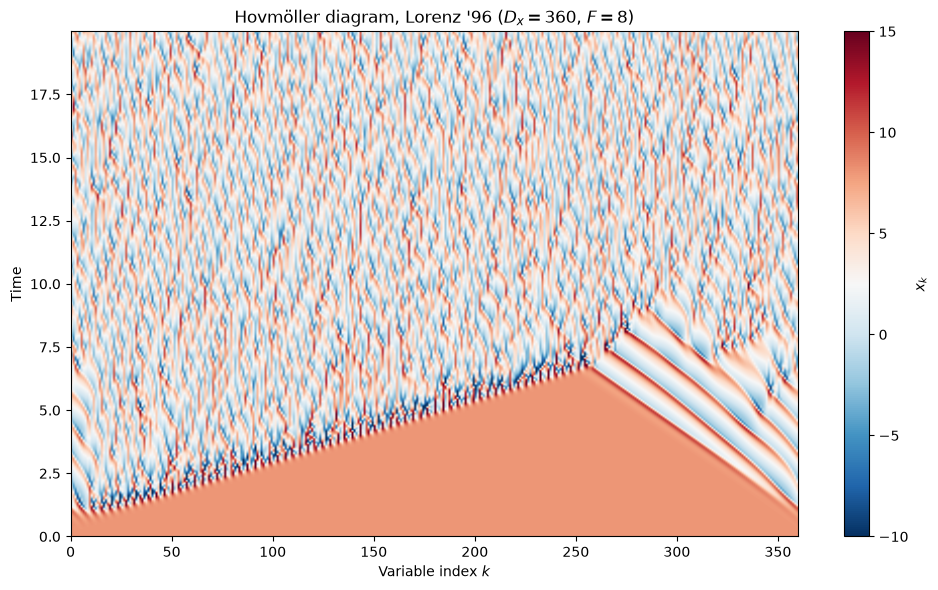

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
image = ax.imshow(
    solution.ys.x,
    aspect="auto",
    origin="lower",
    cmap="RdBu_r",
    vmin=-10,
    vmax=15,
    extent=[0, num_variables, float(save_times[0]), float(save_times[-1])],
    interpolation="bilinear",
)
ax.set_xlabel("Variable index $k$")
ax.set_ylabel("Time")
ax.set_title(f"Hovmöller diagram, Lorenz '96 ($D_x={num_variables}$, $F=8$)")
plt.colorbar(image, ax=ax, label="$x_k$")
plt.tight_layout()
plt.show()

## 4. Time series and statistics

Individual variables look like noisy oscillations. The spatial mean settles well below $F$, and the energy budget says by how much. The quadratic term conserves $E$, so averaging $\mathrm{d}E / \mathrm{d}t = -\sum_k x_k^2 + F \sum_k x_k$ over a long run gives $\langle x^2 \rangle = F \langle x \rangle$, which is the check printed below over the second half of the run.

Mean of x over t >= 10: 2.37
<x^2> = 18.92, F <x> = 18.93


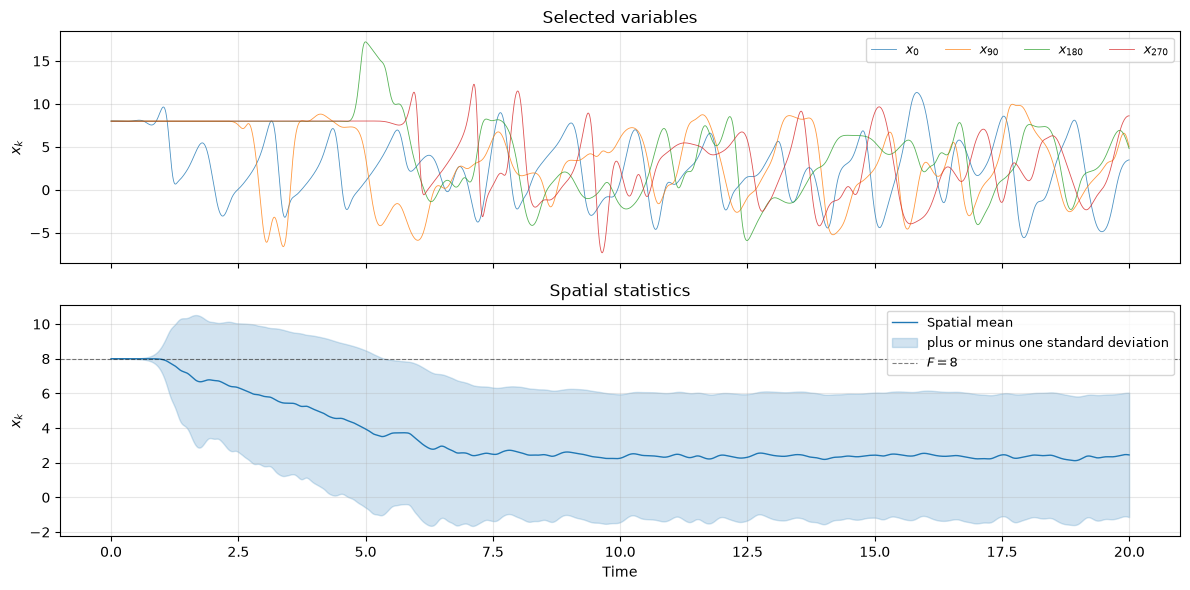

In [7]:
# Shapes: D_x = 360 variables; N_T = 4,000 saved snapshots

# x̄(t) = (1 / D_x) ∑ₖ xₖ(t)
spatial_mean = einx.mean("time [k] -> time", solution.ys.x)  # → (N_T,)
# sd over k of xₖ(t)
spatial_std = einx.std("time [k] -> time", solution.ys.x)  # → (N_T,)

settled = solution.ys.x[save_times >= 10.0]  # → (N_T / 2, D_x)
# ⟨x⟩ over t ≥ 10
long_mean = jnp.mean(settled)  # → ()
# ⟨x²⟩ over t ≥ 10
long_square = jnp.mean(settled**2)  # → ()
print(f"Mean of x over t >= 10: {float(long_mean):.2f}")
print(f"<x^2> = {float(long_square):.2f}, F <x> = {float(forcing * long_mean):.2f}")

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

ax = axes[0]
for colour, position in enumerate([0, 90, 180, 270]):
    ax.plot(
        save_times,
        solution.ys.x[:, position],
        lw=0.6,
        alpha=0.8,
        color=f"C{colour}",
        label=f"$x_{{{position}}}$",
    )
ax.set_ylabel("$x_k$")
ax.set_title("Selected variables")
ax.legend(fontsize=9, ncol=4)
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(save_times, spatial_mean, lw=1, color="C0", label="Spatial mean")
ax.fill_between(
    save_times,
    spatial_mean - spatial_std,
    spatial_mean + spatial_std,
    alpha=0.2,
    color="C0",
    label="plus or minus one standard deviation",
)
ax.axhline(forcing, color="k", ls="--", lw=0.8, alpha=0.5, label="$F = 8$")
ax.set_xlabel("Time")
ax.set_ylabel("$x_k$")
ax.set_title("Spatial statistics")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Diagnostics

`model.diagnose()` returns the energy $E = \frac{1}{2} \sum_k x_k^2$ and the spatial mean.

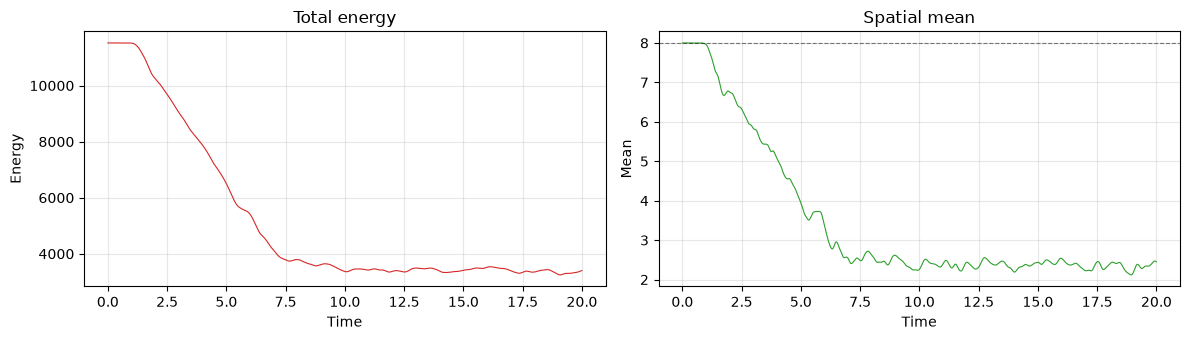

In [8]:
# today (jax, sesmax_core)
diagnostics = jax.vmap(model.diagnose)(solution.ys)  # energy, mean → (N_T,) each

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(save_times, diagnostics.energy, lw=0.8, color="C3")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Energy")
axes[0].set_title("Total energy")
axes[0].grid(True, alpha=0.3)
axes[1].plot(save_times, diagnostics.mean, lw=0.8, color="C2")
axes[1].axhline(forcing, color="k", ls="--", lw=0.8, alpha=0.5)
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Mean")
axes[1].set_title("Spatial mean")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Forcing regimes

The behaviour changes with $F$. We compare three values, with the same initial perturbation size and the same run length. The perturbation starts on a single variable, so each panel shows a front spreading around the ring from there. Behind the front, $F = 2$ gives a regular packet of weak waves, $F = 5$ an irregular pattern, and $F = 8$ the fully chaotic one, and the printed spread over the ring grows with the forcing.

F = 2: std over the ring at t = 20: 0.797


F = 5: std over the ring at t = 20: 2.369


F = 8: std over the ring at t = 20: 3.591


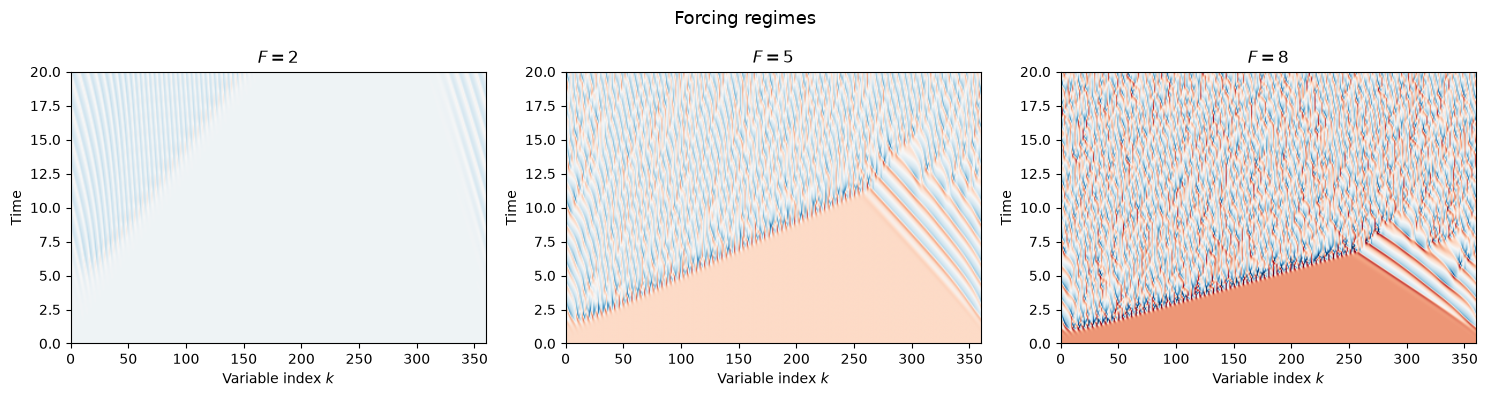

In [9]:
# Shapes: D_x = 360 variables; N_T = 4,000 saved snapshots

regimes = [2.0, 5.0, 8.0]
regime_solutions = {}
for regime in regimes:
    # today (sesmax_core)
    regime_model = sxt.Lorenz96.create(F=regime)
    regime_state = sxt.L96State.init_state(ndim=num_variables, noise=0.01, F=regime)
    # today (sesmax_core, diffrax)
    regime_solutions[regime] = regime_model.integrate(  # x → (N_T, D_x)
        regime_state,
        t0=0.0,
        t1=20.0,
        dt=time_step,
        saveat=dfx.SaveAt(ts=save_times),
    ).ys.x
    # sd over k of xₖ(t₁)
    final_std = einx.std("[k] ->", regime_solutions[regime][-1])  # → ()
    print(f"F = {regime:.0f}: std over the ring at t = 20: {float(final_std):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, regime in zip(axes, regimes, strict=True):
    ax.imshow(
        regime_solutions[regime],
        aspect="auto",
        origin="lower",
        cmap="RdBu_r",
        vmin=-10,
        vmax=15,
        extent=[0, num_variables, 0, 20],
        interpolation="bilinear",
    )
    ax.set_xlabel("Variable index $k$")
    ax.set_ylabel("Time")
    ax.set_title(f"$F={regime:.0f}$")
plt.suptitle("Forcing regimes", fontsize=13)
plt.tight_layout()
plt.show()

## 7. Adjoint methods and differentiation

The [Lorenz '63 page](lorenz63_simulation.ipynb) compares diffrax's adjoint methods. We use the default, `RecursiveCheckpointAdjoint`, here.

### 7a. Gradient with respect to the forcing

**Use case: parameter estimation.** Find the forcing $F$ that minimises a loss $\mathcal{L} = \lVert \mathbf{x}(t_1) \rVert^2$:

$$
\frac{\partial \mathcal{L}}{\partial F} = \int_{0}^{t_1} \boldsymbol{\lambda}(t)^\top \frac{\partial f}{\partial F} \mathrm{d}t
$$

In [10]:
def window_loss(state, model):
    """ℒ = ‖x(t₁)‖², over a one-unit window."""
    # today (sesmax_core, diffrax)
    window = model.integrate(state, t0=0.0, t1=1.0, dt=time_step)  # x → (1, D_x)
    # ℒ = ∑ₖ xₖ(t₁)²
    return jnp.sum(window.ys.x**2)  # → ()


# today (equinox)
# ∂ℒ/∂F
parameter_gradient = eqx.filter_grad(lambda m: window_loss(initial_state, m))(model)
print(f"dL/dF = {float(parameter_gradient.params.F):.4f}")

dL/dF = 3630.4783


### 7b. Gradient with respect to the initial state

**Use case: 4D-Var data assimilation.** Find the initial condition $\mathbf{x}_0$ that best fits observations. The gradient is the adjoint state at $t = 0$:

$$
\nabla_{\mathbf{x}_0} \mathcal{L} = \boldsymbol{\lambda}(0)
$$

In [11]:
# today (jax)
# ∇_x₀ ℒ
state_gradient = jax.grad(window_loss)(initial_state, model)  # x → (D_x,)

# ‖∇_x₀ ℒ‖₂
state_gradient_norm = jnp.sqrt(jnp.sum(state_gradient.x**2))  # → ()
print(f"dL/d(x0) shape: {state_gradient.x.shape}")
print(f"dL/d(x0) norm:  {float(state_gradient_norm):.4f}")

dL/d(x0) shape: (360,)
dL/d(x0) norm:  4228.1694


### 7c. Joint gradient: forcing and state

**Use case: joint estimation.** Optimise the initial condition and the model parameter together, in one backward pass.

In [12]:
# today (jax)
# (∇_x₀ ℒ, ∂ℒ/∂F)
joint_state, joint_model = jax.grad(window_loss, argnums=(0, 1))(initial_state, model)

# ‖∇_x₀ ℒ‖₂
joint_norm = jnp.sqrt(jnp.sum(joint_state.x**2))  # → ()
print(f"dL/dF         = {float(joint_model.params.F):.4f}")
print(f"dL/d(x0) norm = {float(joint_norm):.4f}")

dL/dF         = 3630.4783
dL/d(x0) norm = 4228.1694


## 8. Ensemble forecast divergence

We launch 30 ensemble members from perturbed initial conditions and measure the ensemble spread over time, the hallmark of deterministic chaos.

Spread at t = 2.00: 3.964
Spread at t = 4.00: 3.574
Spread at t = 6.00: 3.562
Spread at t = 9.95: 3.572


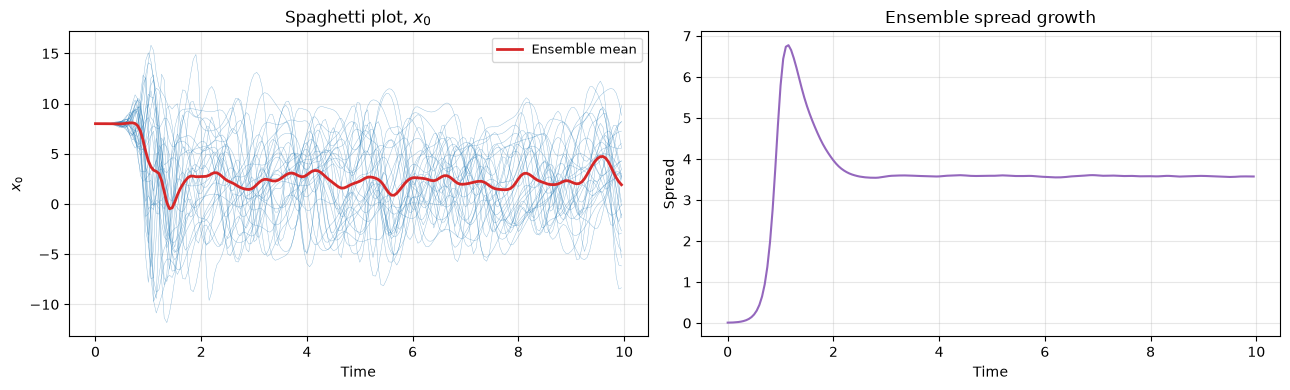

In [13]:
# Shapes: N_E = 30 members; D_x = 360 variables; N_T = 200 saved snapshots

num_members = 30
ensemble_key = jax.random.key(0)

# ε⁽ᵉ⁾ ~ 𝒩(0, 0.01² I)
perturbation = 0.01 * jax.random.normal(ensemble_key, (num_members, num_variables))
# today (sesmax_core)
# x₀⁽ᵉ⁾ = F + ε⁽ᵉ⁾
ensemble_states = sxt.L96State(x=forcing + perturbation)
ensemble_times = jnp.arange(0.0, 10.0, 0.05)  # → (N_T,)


def integrate_member(member_state):
    # today (sesmax_core, diffrax)
    return model.integrate(
        member_state,
        t0=0.0,
        t1=10.0,
        dt=time_step,
        saveat=dfx.SaveAt(ts=ensemble_times),
    )


# today (equinox)
ensemble = eqx.filter_vmap(integrate_member)(ensemble_states)  # x → (N_E, N_T, D_x)

# x̄(t) = (1 / N_E) ∑ₑ x⁽ᵉ⁾(t)
ensemble_mean = einx.mean("[member] time k -> time k", ensemble.ys.x)  # → (N_T, D_x)
# var⁽ᵉ⁾[xₖ(t)]
variance = einx.var("[member] time k -> time k", ensemble.ys.x)  # → (N_T, D_x)
# s(t) = √(mean over k of var⁽ᵉ⁾[xₖ(t)])
spread = jnp.sqrt(einx.mean("time [k] -> time", variance))  # → (N_T,)

for check_time in [2.0, 4.0, 6.0, 9.95]:
    index = int(check_time / 0.05)
    print(f"Spread at t = {check_time:.2f}: {float(spread[index]):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
for member in range(num_members):
    ax.plot(ensemble_times, ensemble.ys.x[member, :, 0], lw=0.3, alpha=0.5, color="C0")
ax.plot(ensemble_times, ensemble_mean[:, 0], lw=2, color="C3", label="Ensemble mean")
ax.set_xlabel("Time")
ax.set_ylabel("$x_0$")
ax.set_title("Spaghetti plot, $x_0$")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(ensemble_times, spread, lw=1.5, color="C4")
ax.set_xlabel("Time")
ax.set_ylabel("Spread")
ax.set_title("Ensemble spread growth")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

The spread has saturated by $t = 4$, at about the variability of the climate itself: beyond that the ensemble mean carries little information about any one member, which is the predictability horizon.

## Summary

| Concept | sesmax API |
| --- | --- |
| Create a model | `Lorenz96.create(F=8.0)` |
| Initial condition | `L96State.init_state(ndim=40, F=8.0)` |
| Forward simulation | `model.integrate(state0, t0, t1, dt, saveat=...)` |
| Diagnostics | `model.diagnose(state)`, the energy and the mean |
| Gradient with respect to the forcing | `eqx.filter_grad(loss)(model)` |
| Gradient with respect to the state | `jax.grad(loss)(state0)` |
| Joint gradient | `jax.grad(loss, argnums=(0, 1))(state0, model)` |
| Ensemble | `eqx.filter_vmap(integrate_member)(batch_states)` |

**Next:** [Lorenz '96 two-tier](lorenz96t_simulation.ipynb) couples these slow variables to fast ones.